## Figure 1
- a) 6-Month Avg Forecast
- b) Signal-to-noise ratio
- c) Monthly Land-Avg Forecast
- d) Hot-only Moratlity Rate Map
- e) Cold-only Moratlity Rate Map
- f) Monthly Global Avg Mortality Rate
- g) Box plot by income

### Initialization

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import os
from datetime import datetime, UTC
from dotenv import find_dotenv, load_dotenv
import xarray as xr
import xvec

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator
import cartopy.crs as ccrs

from utils import analysis_utils
from utils import isku_utils
from utils import plotting_utils
from utils import stats_utils

import importlib

importlib.reload(analysis_utils)
importlib.reload(isku_utils)
importlib.reload(plotting_utils)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'utils.plotting_utils' from '/home/emily_zuetell/projects/poreallas/utils/plotting_utils.py'>

In [2]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]
IMPACT_REGION_POLYGONS = os.environ["POREALLAS_REGIONS_POLYGONS_URI"]
SOCIOECONOMICS_URI = os.environ["POREALLAS_SOCIOECONOMICS_URI"]

# Climate Data
TAS_FORECAST_URI = os.environ["POREALLAS_TAS_FORECAST_URI"]
ERA5_URI = os.environ["POREALLAS_ERA5_URI"]
TAS_FORECAST_RAW = os.environ["POREALLAS_PARSED_FORECAST_URI"]

In [3]:
# Baseline period for Impact
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
BASELINE_PERIOD = analysis_utils.get_baseline_period(effect, years=30)
# Define Forecast Months
FC_MONTHS = [10, 11, 12, 1, 2, 3]
FC_PERIOD = slice("2026-10-01", "2027-03-31")

config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=True,
    age_weight = True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

## Figure 1

Main Results Fig

In [4]:
### Seasonal Forecast ###
forecast = xr.open_zarr("../data/v2610/v20261006_parsed_forecast.zarr") # Daily ensemble member temp
hindcast = xr.open_zarr("../data/v2610/v20261006_parsed_hindcast.zarr") # Daily ensemble mean temp
# Monthly avg temp
forecast = forecast.groupby('time.month').mean().sel(month = config.months)
hindcast = hindcast.groupby('time.month').mean()
#Monthly anomaly relative to 1996-2025 climatological baseline
fc_anomaly = forecast["tas"] - hindcast["tas"]

In [5]:
# Clip Grid to Land Only
fc_land = analysis_utils.land_only((fc_anomaly), lat_name="lat", lon_name="lon", clip_antarctica=False) # Leave Antarctica in computation
fc_land_mean = analysis_utils.compute_area_weighted_mean(fc_land, lat_name="lat", lon_name="lon")

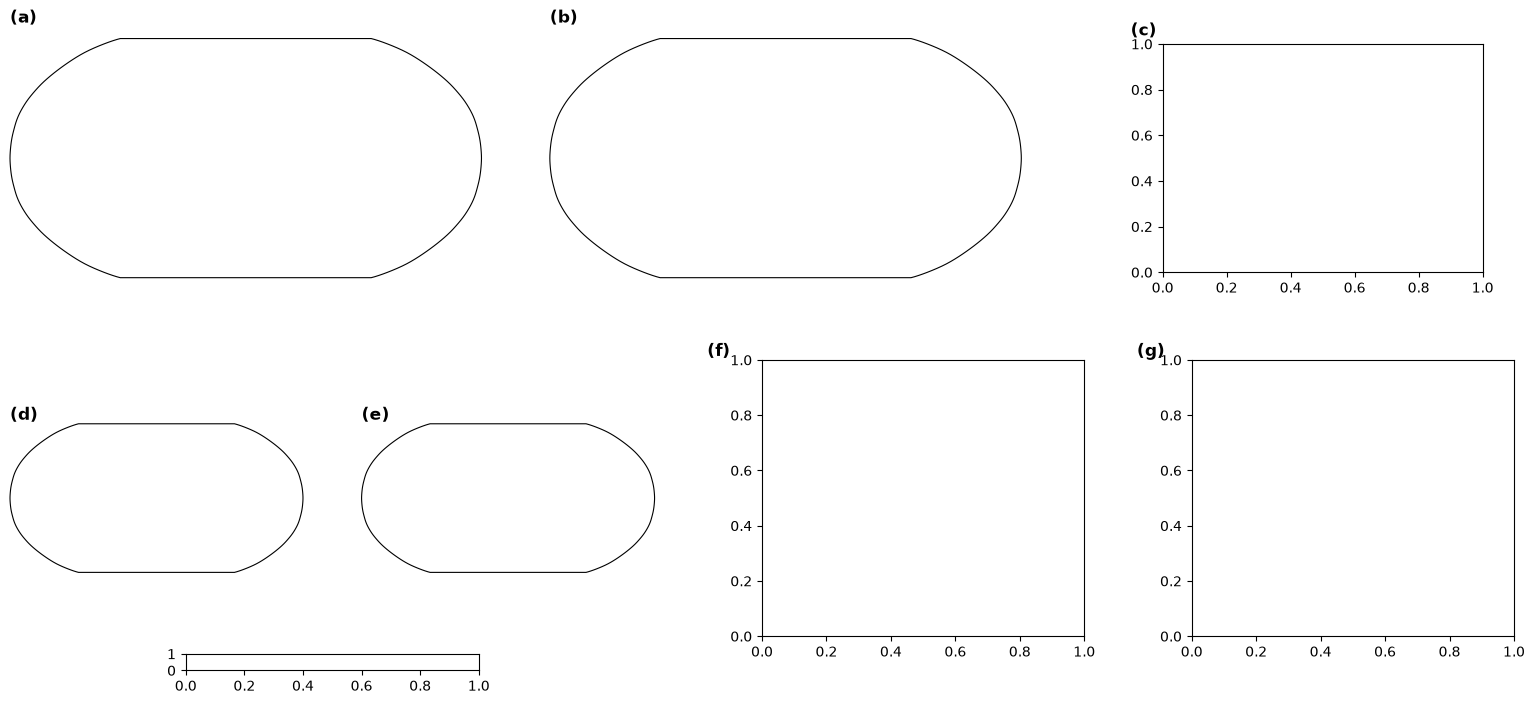

In [6]:
### Build Gridspec ###
fig = plt.figure(figsize=(16, 7.5))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 1], hspace=0.15,
                      left=0.03, right=0.97, top=0.95, bottom=0.06)

# ---- Row 1: (a), (b), (c) side by side ----
gs1 = gs[0].subgridspec(1, 3, width_ratios=[1, 1, 0.9], wspace=0.15)

ax_map1 = fig.add_subplot(gs1[0], projection=ccrs.Robinson())
ax_map2 = fig.add_subplot(gs1[1], projection=ccrs.Robinson())

# Padding rows and columns keep the line plot from stretching to the full cell
gs1_c = gs1[2].subgridspec(3, 3, height_ratios=[0.1, 1, 0.1], width_ratios=[0.15, 1, 0.02])
ax = fig.add_subplot(gs1_c[1, 1])

# ---- Row 2: (b), (c) + shared colorbar, then (d), (e) ----
gs_row2 = gs[1].subgridspec(1, 3, width_ratios=[2, 1, 1], wspace=0.25)

gs_mid = gs_row2[0].subgridspec(2, 4, height_ratios=[1, 0.06], hspace=0.12, wspace=0.5)
ax_b = fig.add_subplot(gs_mid[0, :2], projection=ccrs.Robinson())
ax_c = fig.add_subplot(gs_mid[0, 2:], projection=ccrs.Robinson())
cax_bc = fig.add_subplot(gs_mid[1, 1:3])

# Matching height_ratios keeps (d)/(e) aligned with the maps, not the colorbar
gs_d = gs_row2[1].subgridspec(2, 1, height_ratios=[1, 0.06], hspace=0.12)
gs_e = gs_row2[2].subgridspec(2, 1, height_ratios=[1, 0.06], hspace=0.12)
ax_timeseries = fig.add_subplot(gs_d[0])
ax_extra = fig.add_subplot(gs_e[0])

# ---- Panel labels ----
for label, a in zip("ab", [ax_map1, ax_map2]):
    a.text(0.0, 1.05, f"({label})", transform=a.transAxes,
           fontsize=12, fontweight="bold", va="bottom", ha="left")
ax.text(-0.1, 1.02, "(c)", transform=ax.transAxes,
        fontsize=12, fontweight="bold", va="bottom", ha="left")

for label, a in zip("de", [ax_b, ax_c]):
    a.text(0.0, 1.0, f"({label})", transform=a.transAxes,
           fontsize=12, fontweight="bold", va="bottom", ha="left")
for label, a in zip("fg", [ax_timeseries, ax_extra]):
    a.text(-0.17, 1.0, f"({label})", transform=a.transAxes,
           fontsize=12, fontweight="bold", va="bottom", ha="left")

In [7]:
### Load Forecast Data ###
anom = fc_land.mean(dim = ['month']) # 6-month avg anomaly
ens_mean = anom.mean("number") # ensemble mean

### Signal to Noise Ratio (Impact Region)
fc_ir = isku_utils.grid_to_ir(fc_anomaly.mean(dim = ['month']))
fc_6 = fc_ir     # 6-month mean anomaly per member
signal = fc_6.mean(dim="number")
noise = fc_6.std(dim="number")
snr = signal / noise
snr_df = analysis_utils.xarray_to_gpd(snr, config.polygons)
snr_vec = analysis_utils.region_to_xvec(snr, config.polygons)

### Teleconnection Mask ###
tc_mask = xr.open_zarr("../data/teleconnection_mask_a1_m3.zarr")
tc_mask = 1-tc_mask["__xarray_dataarray_variable__"]
tc_mask = analysis_utils.region_to_xvec(
    tc_mask.squeeze(drop=True),
    config.polygons,
)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3413: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


In [8]:
### Plot Forecast Mean ###
step = 0.5
vmax = np.ceil(float(abs(ens_mean).quantile(0.98)) / step) * step
levels = np.arange(-vmax, vmax + step, step)
# Plot ensemble mean
mesh = ens_mean.plot.pcolormesh(
    ax=ax_map1, transform=ccrs.PlateCarree(),
    cmap="RdBu_r", levels=levels, extend="both",
    add_colorbar=False,
)

ax_map1.coastlines(linewidth=0.6, color="k")
ax_map1.set_global()

fig.colorbar(mesh, ax=ax_map1, orientation="horizontal", shrink=0.6, pad=0.05,
             label="Temperature anomaly (°C)")
# Add Hatching: T-Test across ensemble members, alpha = 0.05
mask = stats_utils.ttest_mask(anom, alpha=0.05)
plotting_utils.add_polygons(ax_map1, mask, transform=ccrs.PlateCarree())

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/array/numpy_compat.py:61: RuntimeWarning: invalid value encountered in divide
  x = np.divide(x1, x2, out)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packa

In [9]:
### Plot Signal-to-Noise Ratio ###
gdf_plot = (
    abs(snr_vec)
    .xvec.to_geodataframe(name="value")
    .to_crs(ax_map2.projection.proj4_init)
)

cmap = "YlOrBr"
levels = [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 5]
norm = mcolors.BoundaryNorm(levels, plt.get_cmap(cmap).N, extend="max")

gdf_plot.plot(column="value", ax=ax_map2, linewidth=0, cmap=cmap, norm=norm)

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax_map2, orientation="horizontal", shrink=0.6, pad=0.03,
             extend="max", label="|Signal-to-noise ratio|")

ax_map2.coastlines(linewidth=0.6, color="k")
ax_map2.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
ax_map2.spines["geo"].set_visible(False)

plotting_utils.add_polygons(
    ax_map2, tc_mask, hatch = "///", outline_color="k", outline_width=1,
    transform=ccrs.PlateCarree(),
)
ax_map2.set_axis_off()


In [10]:
### Plot Land avg anomaly ###
da = fc_land_mean
da = da.assign_coords(
    month=range(len(config.months))
)  # 0..5 positions instead of real month values

# Shaded 5-95 Interval
q = da.quantile([0.05, 0.95], dim='number')

ax.fill_between(
    da['month'],
    q.sel(quantile=0.05),
    q.sel(quantile=0.95),
    color='gray',
    alpha=0.3,
)
# Line Plot
da.plot.line(x = 'month', color = 'gray', 
                    linewidth = 0.5, alpha = 0.5, 
                    ax=ax,
                    add_legend=False)
da.mean(dim = 'number').plot(marker="o", color = 'black', ax=ax)

ax.set_ylim(bottom=0)
ax.set_xticks(range(len(config.months)))
ax.set_xticklabels(config.months)
ax.set_xlabel("Month")
ax.set_ylabel("Land-Average \n Anomaly [C]")
ax.set_title("")

Text(0.5, 1.0, '')

In [11]:
# Spine Removal
ax.spines[['top', 'right']].set_visible(False)
ax_map1.spines['geo'].set_visible(False)
ax_map2.spines['geo'].set_visible(False)

ax.yaxis.set_major_locator(MultipleLocator(0.5))

ax.grid(axis='y', linestyle='--', linewidth=0.5, color='gray', alpha=0.4)
ax.set_axisbelow(True)

In [12]:
# Compute the Mortality Impact relative to a Baseline Period for the Projected Effects
month_order = config.months
cmap = plt.get_cmap("coolwarm")
colors = {"net": 'gray', "hotonly": mcolors.to_hex(cmap(0.85)), "coldonly": mcolors.to_hex(cmap(0.15))}
ax = ax_timeseries
for hotonly in ["net", "hotonly", "coldonly"]:
    impact = analysis_utils.compute_impact(effect.chunk({dim: -1 for dim in config.dims}), 
                                           config,
                                           hotonly = hotonly,
                                           ensemble=True)
    ## Global Pop-Weighted ##
    da = impact.sel(month = config.months)
    pop = config.socioeconomics.pop.sel(region=da.region).fillna(0)
    da = da.weighted(pop).mean(dim='region')
    da = da.assign_coords(
        month=range(len(config.months))
    )  # 0..5 positions instead of real month values

    q = da.quantile([0.05, 0.95], dim=["number", "sample"]).compute()
    ax.fill_between(da.month, q.sel(quantile=0.05), q.sel(quantile=0.95),
                    color=colors[hotonly], alpha=0.25, linewidth=0, zorder=1)
    da.mean(dim=["number", "sample"]).plot(marker="o", ax=ax, label=hotonly, color=colors[hotonly], zorder=10)

ax.axhline(y=0, color="black", linewidth=0.5)
ax.set_xticks(range(len(month_order)))
ax.set_xticklabels(month_order)
ax.set_xlabel("Month")
ax.set_ylabel("6-month Mortality Rate \n[deaths/100k]")
names = {"net": "Net", "hotonly": "Hot Deaths", "coldonly": "Cold Deaths"}
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [names.get(l, l) for l in labels], frameon=False)
ax.set_title("")

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_

Text(0.5, 1.0, '')

In [14]:
### Maps ###
# Compute fields
results = {}
for hotonly in ["net", "hotonly", "coldonly"]:
    impact = analysis_utils.compute_impact(effect.chunk({dim: -1 for dim in config.dims}), 
                                               config,
                                               ensemble=True,
                                               hotonly = hotonly)
    gdf = config.polygons.reset_index()
    gdf["geometry"] = gdf.geometry.make_valid()
    #select only 6-month forecast
    ds = impact.sel(month = config.months)

    geoms = gdf.set_index("region").loc[ds["region"].values, "geometry"]

    ds = (
        ds.assign_coords(geometry=("region", geoms.values))
        .swap_dims(region="geometry")
        .xvec.set_geom_indexes("geometry", crs=gdf.crs)
    )

    ds_6 = ds.sum(dim = ['month']) # 6-month total
    ens_mean = ds_6.mean(dim = ['sample', 'number']) # ensemble mean
    results[hotonly] = (ds_6, ens_mean)

def make_norm(means, step=5):
    all_abs = np.concatenate([abs(m).values.ravel() for m in means])
    vmax = np.ceil(np.nanquantile(all_abs, 0.98) / step) * step
    levels = np.round(np.arange(-vmax, vmax + step / 2, step), 10)
    cmap = plt.get_cmap("RdBu_r", len(levels) - 1 + 2)
    norm = mcolors.BoundaryNorm(levels, cmap.N, extend="both")
    return levels, cmap, norm

scale = make_norm([results["net"][1], results["hotonly"][1], results["coldonly"][1]])

panels = [(ax_b, "hotonly"), (ax_c, "coldonly")]
levels, cmap, norm = scale

for ax, hotonly in panels:
    ds_6, ens_mean = results[hotonly]

    gdf_plot = ens_mean.xvec.to_geodataframe(name="anom").to_crs(ax.projection.proj4_init)
    gdf_plot.plot(column="anom", ax=ax, cmap=cmap, norm=norm, linewidth=0)

    ax.coastlines(linewidth=0.6, color="k")
    ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
    ax.spines["geo"].set_visible(False)
    mask = stats_utils.region_ttest_mask(ds_6, alpha=0.05)
    plotting_utils.add_polygons(ax, mask, transform=ccrs.PlateCarree())
    ax.set_axis_off()

# Colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, cax=cax_bc, orientation="horizontal", extend="both",
                    label="Mortality Rate (deaths/100k)")
cbar.set_ticks(levels[::2])

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_

In [15]:
def weighted_box_stats(vals, weights, whis=1.5):
    # weights = pop/pop_box
    mask = np.isfinite(vals) & np.isfinite(weights)
    v, w = vals[mask], weights[mask]
    order = np.argsort(v)
    v, w = v[order], w[order]
    # Normalize weights within box
    cdf = (np.cumsum(w) - 0.5 * w) / w.sum()
    q1, med, q3 = np.interp([0.25, 0.5, 0.75], cdf, v)
    iqr = q3 - q1
    whislo = v[v >= q1 - whis * iqr].min()
    whishi = v[v <= q3 + whis * iqr].max()
    return dict(med=med, q1=q1, q3=q3, whislo=whislo, whishi=whishi, fliers=[])

In [ ]:
### Box Plot ###
quartile_labels = ["Low income", "Low-middle income", "Middle-high income", "High income"]
quartile_labels_display = [lbl.replace(" ", "\n", 1) for lbl in quartile_labels]

data_by_category = {}
for hotonly in ["net", "hotonly", "coldonly"]:
    impact = analysis_utils.compute_impact(effect.chunk({dim: -1 for dim in config.dims}), 
                                   config,
                                   ensemble=False,
                                   hotonly = hotonly)
    impact = impact.sel(month = config.months)
    #6-month total impact
    impact_mean = impact.sum(dim="month")
    if "number" in impact_mean.dims or "sample" in impact_mean.dims:
        impact_mean = impact_mean.mean(dim=[d for d in ["number", "sample"] if d in impact_mean.dims])

    impact_aligned, gdppc_aligned = xr.align(impact_mean, config.socioeconomics.gdppc, join="inner")
    region_vals = impact_aligned.values

    pop_aligned = config.socioeconomics.pop.sel(region=impact_aligned.region)

    sort_idx = np.argsort(gdppc_aligned.values)
    gdppc_sorted = gdppc_aligned.values[sort_idx]
    pop_sorted = pop_aligned.values[sort_idx]
    # Equal-Population Bins
    cum_pop = np.cumsum(pop_sorted)
    cum_pop_frac = cum_pop / cum_pop[-1]
    breakpoints = np.interp([0.25, 0.5, 0.75], cum_pop_frac, gdppc_sorted)
    bin_edges = np.concatenate([[gdppc_sorted[0] - 1], breakpoints, [gdppc_sorted[-1] + 1]])
    # Cut GDP Quartiles
    quartiles = pd.cut(gdppc_aligned.values, bins=bin_edges, labels=quartile_labels)
    # Within-bin weighting
    pop_vals = pop_aligned.values
    data_by_category[hotonly] = [
        weighted_box_stats(region_vals[quartiles == q], pop_vals[quartiles == q])
        for q in quartile_labels
    ]

ax = ax_extra
positions = []
box_data = []
group_gap = 1
box_width = 0.6
n_quartiles = 4

for i, category in enumerate(["net", "hotonly", "coldonly"]):
    for j, q_data in enumerate(data_by_category[category]):
        positions.append(i * (n_quartiles + group_gap) + j)
        box_data.append(q_data)

bp = ax.bxp(
    box_data,
    positions=positions,
    widths=box_width,
    patch_artist=True,
    medianprops=dict(color="black"),
    showfliers=False,
)

for patch, color in zip(bp['boxes'], [colors[c] for c in ["net", "hotonly", "coldonly"] for _ in range(n_quartiles)]):
    patch.set_facecolor(color)

group_centers = [i * (n_quartiles + group_gap) + (n_quartiles - 1) / 2 for i in range(3)]

ax.set_ylim(-30, 30)
ax.set_xticks(positions)
ax.set_xticklabels(["L", "LM", "UM", "H"] * 3, fontsize=7, rotation=45)
ax.tick_params(axis="x", length=0)

ax.axhline(y=0, color="black", linewidth=0.5)
ax.set_ylabel("6-month Mortality Rate \n[deaths/100k]")

sec = ax.secondary_xaxis(-0.2)
sec.set_xticks(group_centers)
sec.set_xticklabels(["Net", "Hot", "Cold"])
sec.tick_params(length=0)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


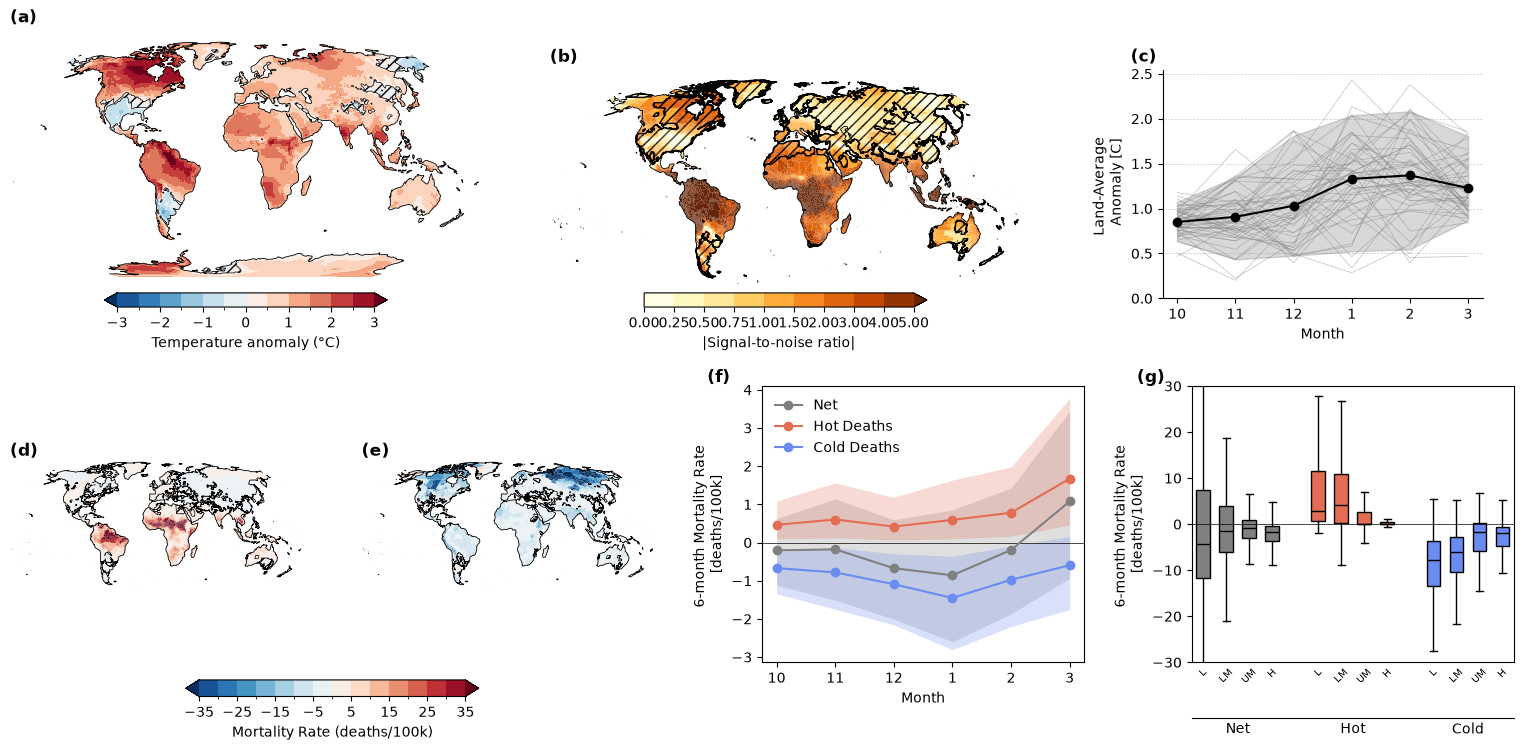

In [ ]:
fig

In [ ]:
fig.savefig(f"{config.version}_fig01_2610.png", dpi=600, bbox_inches="tight")